# 03 — iMAGE | Final evaluation and deployment

**Dataset:** 5,000 real-noise SIDD + PolyU pairs: 4,000 train / 500 validation / **500 untouched test** (350 SIDD + 150 PolyU). All three fine-tuned checkpoints must be evaluated on the **same test pairs**. Run **top to bottom**.

**Important methodology:** The current `app.experiments.evaluate_model` determines preprocessing (including `PATCH` and `TILE`). Results are only full-image metrics if that function actually evaluates complete image areas with tiling; otherwise report *patch-based test PSNR/SSIM*, not full-resolution performance. Review before final thesis reporting.

## Step 1 — Project, device, and verified manifest

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / "app").is_dir():
    ROOT = ROOT.parent.resolve()
if not (ROOT / "app").is_dir():
    raise FileNotFoundError("Open the iMAGE project folder or its notebooks/ directory in VS Code.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("Project:", ROOT)

Project: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final


In [2]:
import pandas as pd
import torch
from app.experiments import setup_device
DEVICE = setup_device()
manifest = ROOT / "data" / "splits.csv"
if not manifest.exists():
    raise FileNotFoundError(manifest)
df = pd.read_csv(manifest)
required = {"dataset", "split", "noisy_path", "clean_path"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")
print("Device:", DEVICE, "| CUDA available:", torch.cuda.is_available())
print("\nSplits:", df["split"].value_counts().to_dict())
print("\nSource allocation:\n", pd.crosstab(df["dataset"], df["split"]))
expected = {"train": 4000, "val": 500, "test": 500}
assert df["split"].value_counts().to_dict() == expected, "Split totals differ from finalized dataset!"
test_df = df[df["split"] == "test"]
assert len(test_df) == 500
assert test_df["dataset"].value_counts().to_dict() == {"SIDD": 350, "PolyU": 150}, "Test source allocation differs!"
assert test_df[["noisy_path", "clean_path"]].notna().all().all()
assert not test_df.duplicated(subset=["dataset", "noisy_path", "clean_path"]).any()
for col in ("noisy_path", "clean_path"):
    paths = test_df[col].map(lambda p: ROOT / str(p))
    missing_files = [str(p) for p in paths if not p.is_file()]
    if missing_files:
        raise FileNotFoundError(f"Missing {col} files (first three): {missing_files[:3]}")
print("\nDataset and test image paths: PASSED")

Device: cuda | CUDA available: True

Splits: {'train': 4000, 'val': 500, 'test': 500}

Source allocation:
 split    test  train  val
dataset                  
PolyU     150   1200  150
SIDD      350   2800  350

Dataset and test image paths: PASSED


c:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2 — Select checkpoints and evaluation mode

Start with `RUN_MODE="smoke"` (5 test pairs per model). Then change to `"full"` (all 500) and rerun Steps 2–4. **Only full mode is eligible for reporting or deployment.**

In [7]:
from app.models import NAMES
from app.experiments import evaluate_model, summaries_as_dataframe

RUN_MODE = "full"   # First smoke; switch to "full" for your FINAL results
PATCH = 256          # Actual test image coverage depends on evaluate_model's implementation
TILE = 256
SEED = 42
SIGMA = 25          # Legacy function argument; ignored for paired real-noise data

if RUN_MODE not in ("smoke", "full"):
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")
LIMIT = 5 if RUN_MODE == "smoke" else 0  # 0 means every test pair
models = ("dncnn", "nafnet", "restormer")
assert set(models) == set(NAMES), f"Check model identifiers: NAMES={NAMES}"
checkpoints = {name: ROOT / "weights" / f"{name}_finetuned.pth" for name in models}
missing = [str(p) for p in checkpoints.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Fine-tuned checkpoints missing:\n" + "\n".join(missing))
for name, path in checkpoints.items():
    print(f"{name}: {path} ({path.stat().st_size / 1024**2:.1f} MiB)")
print(f"\nMode: {RUN_MODE} | Test samples/model: {'all 500' if LIMIT == 0 else LIMIT}")

dncnn: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\dncnn_finetuned.pth (2.6 MiB)
nafnet: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\nafnet_finetuned.pth (111.5 MiB)
restormer: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\restormer_finetuned.pth (99.8 MiB)

Mode: full | Test samples/model: all 500


## Step 3 — Evaluate all three models

Runs sequentially on the **same fixed test split**. Check output for errors. GPU timing should be interpreted according to implementation (warmup/synchronization are important).

In [8]:
summaries = []
for name in models:
    print("\n" + "="*64)
    print(f"Evaluating {name.upper()} — {RUN_MODE} mode")
    result = evaluate_model(
        name,
        checkpoint=checkpoints[name],
        patch=PATCH,
        sigma=SIGMA,
        seed=SEED,
        limit=LIMIT,
        tile=TILE,
    )
    summaries.append(result)
    print(f"Completed: {name}")
print("\nEvaluation completed for:", models)


Evaluating DNCNN — full mode


Testing dncnn: 100%|██████████| 500/500 [00:19<00:00, 25.62it/s]


{
  "model": "dncnn",
  "checkpoint": "C:\\Users\\rmclo\\OneDrive\\Documents\\GitHub\\CCS250_CompVis_Final\\weights\\dncnn_finetuned.pth",
  "checkpoint_sha256": "7ca1d2277e4089f83f386184500153af4f56487db59ade1e3ba8b5dd6a8a17be",
  "manifest_sha256": "574b2f63fd3c509c8f4b11ab9a82520195bb27bc0235abc9a67ea52b8ff67ea6",
  "split": "test",
  "number_of_test_images": 500,
  "limited_test": false,
  "sigma": 25,
  "patch": 256,
  "seed": 42,
  "tile": 256,
  "device": "cuda",
  "psnr_db": 37.7557,
  "ssim": 0.91514,
  "mean_runtime_ms": 13.06,
  "parameters_m": 0.668
}
Completed: dncnn

Evaluating NAFNET — full mode


Testing nafnet: 100%|██████████| 500/500 [00:30<00:00, 16.31it/s]


{
  "model": "nafnet",
  "checkpoint": "C:\\Users\\rmclo\\OneDrive\\Documents\\GitHub\\CCS250_CompVis_Final\\weights\\nafnet_finetuned.pth",
  "checkpoint_sha256": "e3e454ffbd41e97f822c48838cb0820e121649ff47afc381a902aabc491c955d",
  "manifest_sha256": "574b2f63fd3c509c8f4b11ab9a82520195bb27bc0235abc9a67ea52b8ff67ea6",
  "split": "test",
  "number_of_test_images": 500,
  "limited_test": false,
  "sigma": 25,
  "patch": 256,
  "seed": 42,
  "tile": 256,
  "device": "cuda",
  "psnr_db": 41.5418,
  "ssim": 0.956,
  "mean_runtime_ms": 37.97,
  "parameters_m": 29.16
}
Completed: nafnet

Evaluating RESTORMER — full mode


Testing restormer: 100%|██████████| 500/500 [00:57<00:00,  8.72it/s]


{
  "model": "restormer",
  "checkpoint": "C:\\Users\\rmclo\\OneDrive\\Documents\\GitHub\\CCS250_CompVis_Final\\weights\\restormer_finetuned.pth",
  "checkpoint_sha256": "1bab410d04f59f4c0b4d074f267fb2df6ea7c2a3ad766d0ee6b17ec307689636",
  "manifest_sha256": "574b2f63fd3c509c8f4b11ab9a82520195bb27bc0235abc9a67ea52b8ff67ea6",
  "split": "test",
  "number_of_test_images": 500,
  "limited_test": false,
  "sigma": 25,
  "patch": 256,
  "seed": 42,
  "tile": 256,
  "device": "cuda",
  "psnr_db": 40.0678,
  "ssim": 0.94694,
  "mean_runtime_ms": 88.69,
  "parameters_m": 26.112
}
Completed: restormer

Evaluation completed for: ('dncnn', 'nafnet', 'restormer')


## Step 4 — View and verify comparison

Current mode: full


,model,number_of_test_images,psnr_db,ssim,mean_runtime_ms,parameters_m
0,restormer,500,40.0678,0.94694,88.69,26.112
1,dncnn,500,37.7557,0.91514,13.06,0.668
2,nafnet,500,41.5418,0.95600,37.97,29.160


All three 500-image results available: PASSED


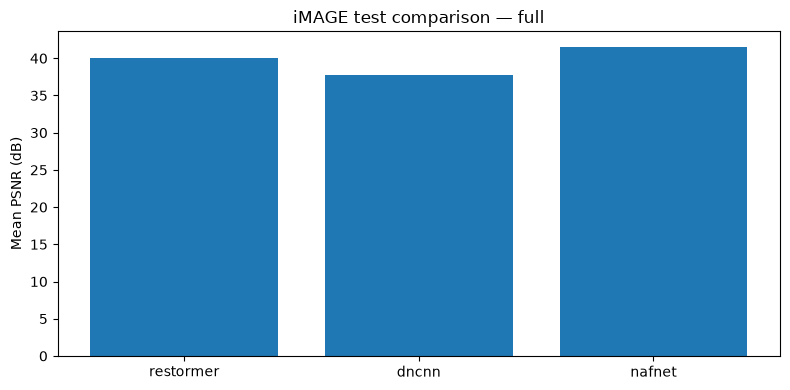

Graph: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\results\comparison_psnr_full.png


In [10]:
import matplotlib.pyplot as plt
frame = summaries_as_dataframe()
if frame.empty:
    raise RuntimeError("No saved evaluation summaries. Run Step 3 first.")
needed = ["model", "number_of_test_images", "psnr_db", "ssim", "mean_runtime_ms", "parameters_m"]
missing = [c for c in needed if c not in frame.columns]
if missing:
    raise KeyError(f"Summary columns missing: {missing}. Available: {list(frame.columns)}")
result_frame = frame[frame["model"].isin(models)].copy()
# Existing result files can contain runs from other sessions: only accept one row/model
print(f"Current mode: {RUN_MODE}")
display(result_frame[needed])
if RUN_MODE == "full":
    final_rows = result_frame[result_frame["number_of_test_images"] == 500]
    assert set(final_rows["model"]) == set(models), "Not all models have a 500-image result!"
    assert not final_rows.duplicated("model").any(), "Duplicate 500-image summaries; clean up stale files before reporting."
    print("All three 500-image results available: PASSED")
else:
    print("SMOKE TEST ONLY — Do not use this run for final results or deployment.")

plot_frame = result_frame if RUN_MODE == "smoke" else result_frame[result_frame["number_of_test_images"] == 500]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(plot_frame["model"], plot_frame["psnr_db"])
ax.set(ylabel="Mean PSNR (dB)", title=f"iMAGE test comparison — {RUN_MODE}")
fig.tight_layout()
result_dir = ROOT / "results"
result_dir.mkdir(parents=True, exist_ok=True)
figure_path = result_dir / f"comparison_psnr_{RUN_MODE}.png"
fig.savefig(figure_path, dpi=160)
plt.show()
print("Graph:", figure_path)

## Step 5 — Deploy final models (optional)

**Only after a completed full evaluation.** Copies fine-tuned checkpoints to the local names preferred by the web API. This overwrites any existing `weights/{model}.pth`; backups are made when those files exist. Run only if you intend to enable real model inference in the web app.

In [12]:
from pathlib import Path
import shutil
DEPLOY_FINETUNED = True  # Intentionally disabled until final results are reviewed
if DEPLOY_FINETUNED:
    if RUN_MODE != "full" or LIMIT != 0:
        raise RuntimeError("Deployment requires RUN_MODE='full' and LIMIT=0")
    final_rows = result_frame[result_frame["number_of_test_images"] == 500]
    if set(final_rows["model"]) != set(models) or final_rows.duplicated("model").any():
        raise RuntimeError("A verified 500-image result is needed for each model")
    for name, source in checkpoints.items():
        target = ROOT / "weights" / f"{name}.pth"
        if target.exists():
            backup = target.with_suffix(".pth.backup")
            shutil.copy2(target, backup)
            print("Backup:", backup)
        shutil.copy2(source, target)
        print("Deployed:", target)
    print("Deployment completed. Restart FastAPI and verify IMAGE_MODE=real configuration.")
else:
    print("Deployment disabled; no model files changed.")

Deployed: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\dncnn.pth
Deployed: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\nafnet.pth
Deployed: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\restormer.pth
Deployment completed. Restart FastAPI and verify IMAGE_MODE=real configuration.


## Reporting checklist

- State **SIDD + PolyU real-world paired noise**, not synthetic Gaussian σ=25.
- State dataset split: **4,000 train / 500 validation / 500 test** and test composition **350 SIDD / 150 PolyU**.
- State test resolution / crop policy. **Do not call PATCH=256 full-resolution evaluation without verifying `evaluate_model`.**
- Include mean PSNR and SSIM, runtime measurement method, parameters, device, checkpoints, training settings, and comparisons with pretrained baselines if available.
- Avoid selecting hyperparameters or checkpoints using the 500-image test results; model selection should use the validation split.
- Only deploy after verifying outputs and model behavior on sample images.